In [63]:
import geopandas as gpd
import pandas as pd
from glob import glob
from matplotlib import pyplot as plt
import matplotlib.patches as mpatches
from shapely.ops import unary_union


In [2]:
sp = gpd.read_file("../data/sp.geojson")

In [49]:
gdf[gdf['name'].isna()]

,index,geometry,name


In [48]:
gdf["name"].unique()

array(['Perímetro do Parque Tecnológico do Jaguaré',
       'Polo de Economia Criativa – “Distrito Criativo Sé/República”',
       'ZC', 'Raimuno', 'Fernao Dias', 'Cupece', 'Jacu-Pessego', 'ZDE-1',
       'ZPI-1', 'ZDE-2', 'ZPI-2'], dtype=object)

15.982792230285325


/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/geopandas/array.py:1638: UserWarning: CRS not set for some of the concatenation inputs. Setting output's CRS as WGS 84 (the single non-null crs provided).
  return GeometryArray(data, crs=_get_common_crs(to_concat))


14.722234056935871 area total, sem sobreposições


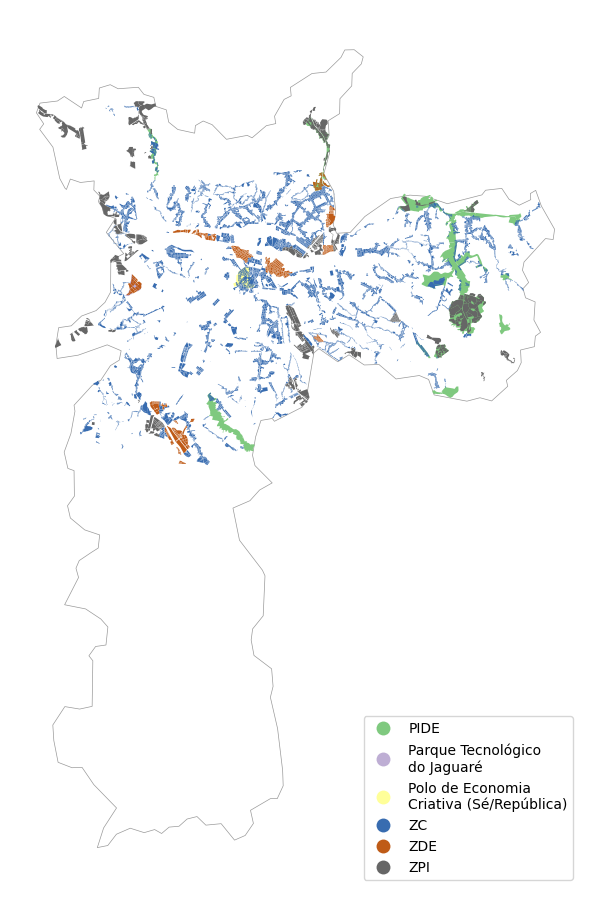

In [65]:


filepath = "../data/economicZones/raw/"
gdf = []

for _filepath in glob(filepath+"*/*.shp", recursive=True):
    _df = gpd.read_file(_filepath).reset_index()
    if 'NOME' in _df.columns: _df = _df.rename(columns={"NOME": "ZONA"})
    gdf.append(_df)
    
gdf = gpd.GeoDataFrame(pd.concat(gdf))[["index", "geometry", "ZONA"]].rename(columns={"ZONA": "name"})
gdf = gdf.set_crs(31983, allow_override=True)
gdf = gdf.to_crs(4326)

myPolygons = pd.read_csv(filepath+"perimetros_criativa.csv")
myPolygons = myPolygons.reset_index().rename(columns={"nome": 'name'})
myPolygons["geometry"] = gpd.GeoSeries.from_wkt(myPolygons.WKT)
myPolygons = gpd.GeoDataFrame(myPolygons)[["index", "geometry", 'name']]
_myPolygons = myPolygons.set_crs(4326, allow_override=True)
_myPolygons = _myPolygons.to_crs(31983)

gdf = gpd.GeoDataFrame(pd.concat([myPolygons, gdf]))

gdf.loc[gdf['name']=="Cupece", "name"] = "PIDE"
gdf.loc[gdf['name']=="Fernao Dias", "name"] = "PIDE"
gdf.loc[gdf['name']=="Jacu-Pessego", "name"] = "PIDE"
gdf.loc[gdf['name']=="Raimuno", "name"] = "PIDE"
gdf.loc[gdf['name'].str.contains("ZDE-"), "name"] = "ZDE"
gdf.loc[gdf['name'].str.contains("ZPI-"), "name"] = "ZPI"
gdf.loc[gdf['name'].str.contains("Jaguaré"), "name"] = "Parque Tecnológico\ndo Jaguaré"
gdf.loc[gdf['name'].str.contains("Criativa"), "name"] = "Polo de Economia\nCriativa (Sé/República)"
gdf = gdf.sort_values("name")

_gdf = gdf.set_crs(4326, allow_override=True)
_gdf = _gdf.to_crs(31983)

geometria_unificada = unary_union(_gdf.geometry)

# Calcula a área total única
area_total_unica = geometria_unificada.area/10e6
print(area_total_unica, 'area total, sem sobreposições')


ax = gdf.plot(column=gdf['name'], zorder=3, figsize=(6, 12), edgecolor='none', cmap='Accent', legend=True, legend_kwds={"loc":'lower right'})
sp.plot(ax=ax, alpha=0.8, color='white', edgecolor='gray', linewidth=0.5, zorder=1)
plt.axis('off')
plt.tight_layout()
plt.savefig("zonas_economicas.png", dpi=900)

5.503330357497081
['gray' '#4575b4']


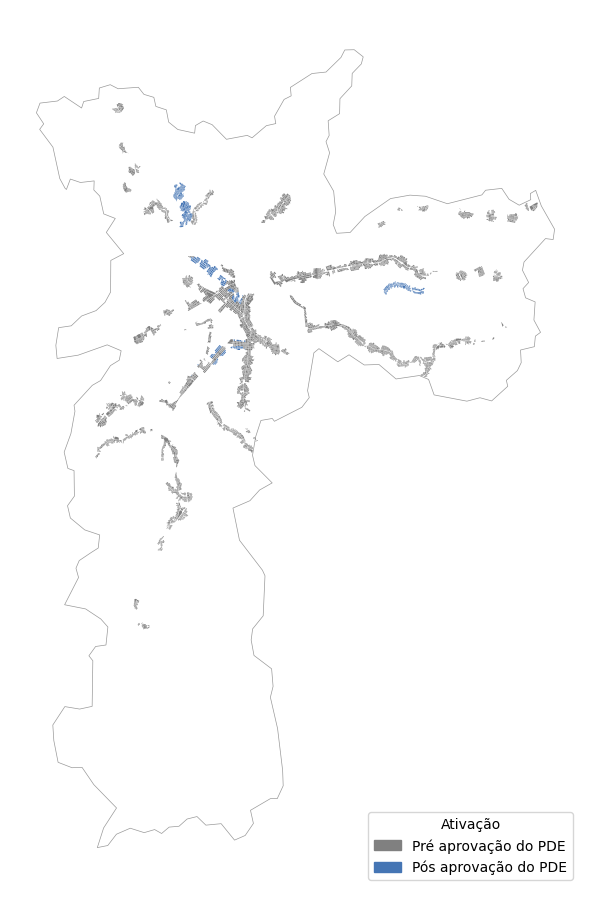

In [29]:
filepath = "../data/eetu/raw/"
first = gpd.read_file(filepath+'sirgas_PDE_3-Eixos-EETU.shp')
late = gpd.read_file(filepath+'SIRGAS_SHP_eixoativodecreto_polygon.shp')

first['year'] = "2013"
late['year'] = late.ed_decreto.apply(lambda string: str(string.split('/')[-1]))
eetu = pd.concat([first[['geometry', 'year']], late[['geometry', 'year']]])
eetu = gpd.GeoDataFrame(eetu)
eetu = eetu.set_crs(31983, allow_override=True)
print(eetu.area.sum()/10e6)
eetu = eetu.to_crs(4326)

mapa_cores = {
    "Pré aprovação do PDE": 'gray',   # vermelho
    "Pós aprovação do PDE": '#4575b4'   # azul
}

def getColor(year):
    if year < '2014': return mapa_cores["Pré aprovação do PDE"]
    return mapa_cores["Pós aprovação do PDE"]
eetu['cor'] = eetu['year'].map(getColor)
print(eetu.cor.unique())
ax = eetu.plot(color=eetu['cor'], zorder=3, figsize=(6, 12), edgecolor='none')
sp.plot(ax=ax, alpha=0.8, color='white', edgecolor='gray', linewidth=0.5, zorder=1)

legenda = [
    mpatches.Patch(color=cor, label=cat)
    for cat, cor in mapa_cores.items()
]

# Adicionando a legenda ao gráfico
ax.legend(handles=legenda, title='Ativação', loc='lower right')

plt.axis('off')
plt.tight_layout()
plt.savefig("eetu.png", dpi=900)
